## UTILITIES

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

## FUNCTION

In [4]:
def plot_line_with_kde(ax, Z, frames, window=51,
                   line_color='black', kde_color='purple',xlab=None,ylab=None):
    """
    Plot time series with moving average + KDE on right.

    Parameters
    ----------
    ax : matplotlib Axes
        Axes object where the plot should be drawn.
    Z : array (N_frames, N_residues)
        Twist or other per-residue metric.
    frames : array
        Frame numbers matching Z rows.
    window : int
        Moving average window.
    """

    # --- Compute main signal ---
    y = Z

    kernel = np.ones(window)/window
    y_smooth = np.convolve(y, kernel, mode='valid')
    pad = (window - 1) // 2
    frames_valid = frames[pad : -pad]

    # --- PLOT LEFT AXIS (main time series) ---
    ax.plot(frames, y, color=kde_color, alpha=0.3, label='Original')
    ax.plot(frames_valid, y_smooth, color=line_color, linewidth=2,
            label='Moving Average')
    ax.set_xlabel(f"{xlab}")
    ax.set_ylabel(f"{ylab}")
    ax.legend(loc='upper left')

    # --- RIGHT AXIS (KDE) ---
    ax2 = ax.twinx()

    kde = gaussian_kde(y)
    y_grid = np.linspace(min(y), max(y), 300)
    density = kde(y_grid)

    # KDE width
    width = (ax.get_xlim()[1] - ax.get_xlim()[0]) * 0.15
    right_border = ax.get_xlim()[1]

    # Scale density
    density_scaled = right_border + (density / density.max()) * width

    # Move right spine to KDE baseline
    ax2.spines['right'].set_position(("data", right_border))

    # Plot KDE + fill
    ax2.plot(density_scaled, y_grid, color=line_color, linewidth=2)
    ax2.fill_betweenx(y_grid, right_border, density_scaled,
                      color=kde_color, alpha=0.25)

    # --- KDE PEAK ---
    idx_peak = np.argmax(density)
    y_peak = y_grid[idx_peak]

    x0 = right_border
    x1 = right_border + (density[idx_peak] / density.max()) * width

    ax2.plot([x0, x1], [y_peak, y_peak],
             color=line_color, linestyle='--', linewidth=2)

    # Label the peak
    ax2.text(x1 * 1.003, y_peak * 1.0008, f"{y_peak:.2f}",
             va='bottom', ha='left', fontsize=9)
    ax.set_xticks([i for i in range(0,frames.shape[0],min(frames.shape[0]//5,250))])

    # Optional: you can customize ax2 ticks here if needed
    return ax, ax2

def plot_new_surface(fig, ax, subplot_index, Z, frames=None, residues=None,
                       cmap='viridis',xlab=None,ylab=None,zlab=None, title="Twist v Frames v Residues"):
    """
    Replace ax with a 3D surface plot using the SAME subplot index.
    Prevents label clipping and works with tight_layout().
    """

    if frames is None:
        frames = np.arange(Z.shape[0])
    if residues is None:
        residues = np.arange(Z.shape[1])

    X, Y = np.meshgrid(residues, frames)

    # --- Remove old 2D axis ---
    fig.delaxes(ax)

    # --- Create NEW 3D axis using the same subplot slot ---
    ax3d = fig.add_subplot(subplot_index, projection='3d')

    # Plot
    surf = ax3d.plot_surface(
        X, Y, Z,
        cmap=cmap,
        edgecolor='none'
    )

    #ax3d.set_zticks([i for i in range(int(np.min(Z)),int(np.max(Z)),int((np.max(Z)-np.min(Z))/5))])
    ax3d.set_xlabel(f"{xlab}")
    ax3d.set_ylabel(f"{ylab}")
    ax3d.set_zlabel(f"{zlab}",rotation=90)
    ax3d.set_title(title)

    fig.colorbar(surf, ax=ax3d, shrink=0.5,pad=0.01,location='left')

    # box = ax3d.get_position()
    # cb_height = 0.025  # height of the colorbar
    # cb_padding = 0.1  # spacing below the plot

    # cax = fig.add_axes([
    #     box.x0,               # left
    #     box.y0 - cb_padding, # bottom
    #     box.width,           # width matches plot
    #     cb_height            # height of colorbar
    # ])

    # fig.colorbar(surf, cax=cax, orientation='horizontal')

    return ax3d


def make_figure1(data,param_name):

    
    frames = np.arange(data.shape[0])
    residues = np.arange(data.shape[1])
    Z = data
    
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    axs = axs.flatten()
    
    # Convert first subplot into a 3D surface plot
    #ax3d = plot_surface(fig, axs[0], Z, frames, residues,xlab='Frames',ylab='Residues',zlab=f'{param_name}',title=f'{param_name} v Frames v Residues')
    ax3d = plot_new_surface(fig, axs[0], 131, Z, frames, residues,cmap='viridis',xlab='Frames',ylab='Residues',zlab=f'{param_name}', title=f'{param_name} v Frames v Residues')
    plot_line_with_kde(axs[1], np.mean(Z,axis=1), frames, xlab='Frames',ylab=f'Average {param_name} per Residue')
    plot_line_with_kde(axs[2], np.mean(Z,axis=0), residues, xlab='Residues',ylab=f'Average {param_name} per Frame')

    plt.tight_layout()


## LOAD DATA

In [8]:
pos = np.load('cg_helix_parameters_positive.npz')
pos_step = pos['step_parameters']
pos_twist = pos_step[:,1:,-1]             #all frames, skipping res1, -1:twist
pos_rise = pos_step[:,1:,2]               #all frames, skipping res1, -1:rise

## MAKE FIGURE

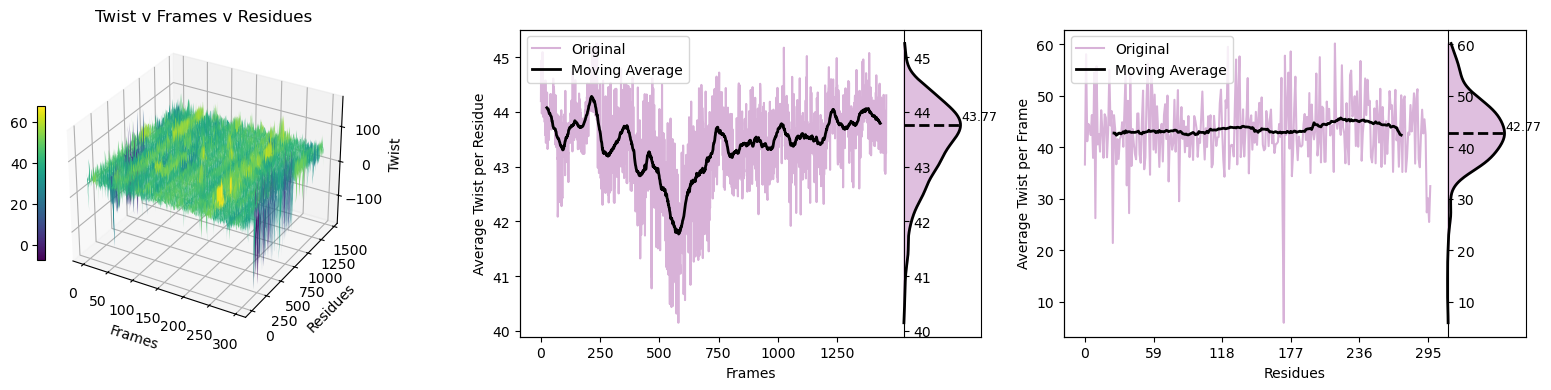

In [10]:
make_figure1(pos_twist,'Twist')                     #(data,'param_name')

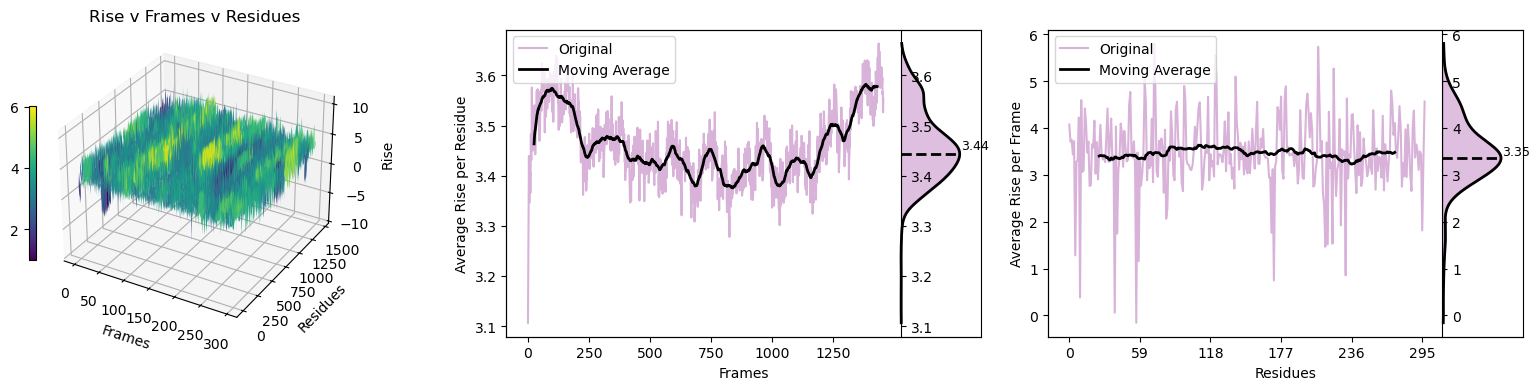

In [9]:
make_figure1(pos_rise,'Rise')